In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

SEED = 987

DIR_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))

%load_ext autoreload
%autoreload 2

In [2]:
import data

listings = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

df = listings.copy()

In [13]:
def square_feet(house_area):
    """house_area is text, either one number ("622") or a range ("900-1099").
    Return a number: the number itself, or the middle of the range."""
    parts = house_area.astype(str).str.split("-", expand=True).reindex(columns=[0, 1])
    low = pd.to_numeric(parts[0], errors="coerce")
    high = pd.to_numeric(parts[1], errors="coerce").fillna(low)
    return (low + high) / 2

df["sqft"] = square_feet(df["house_area"])

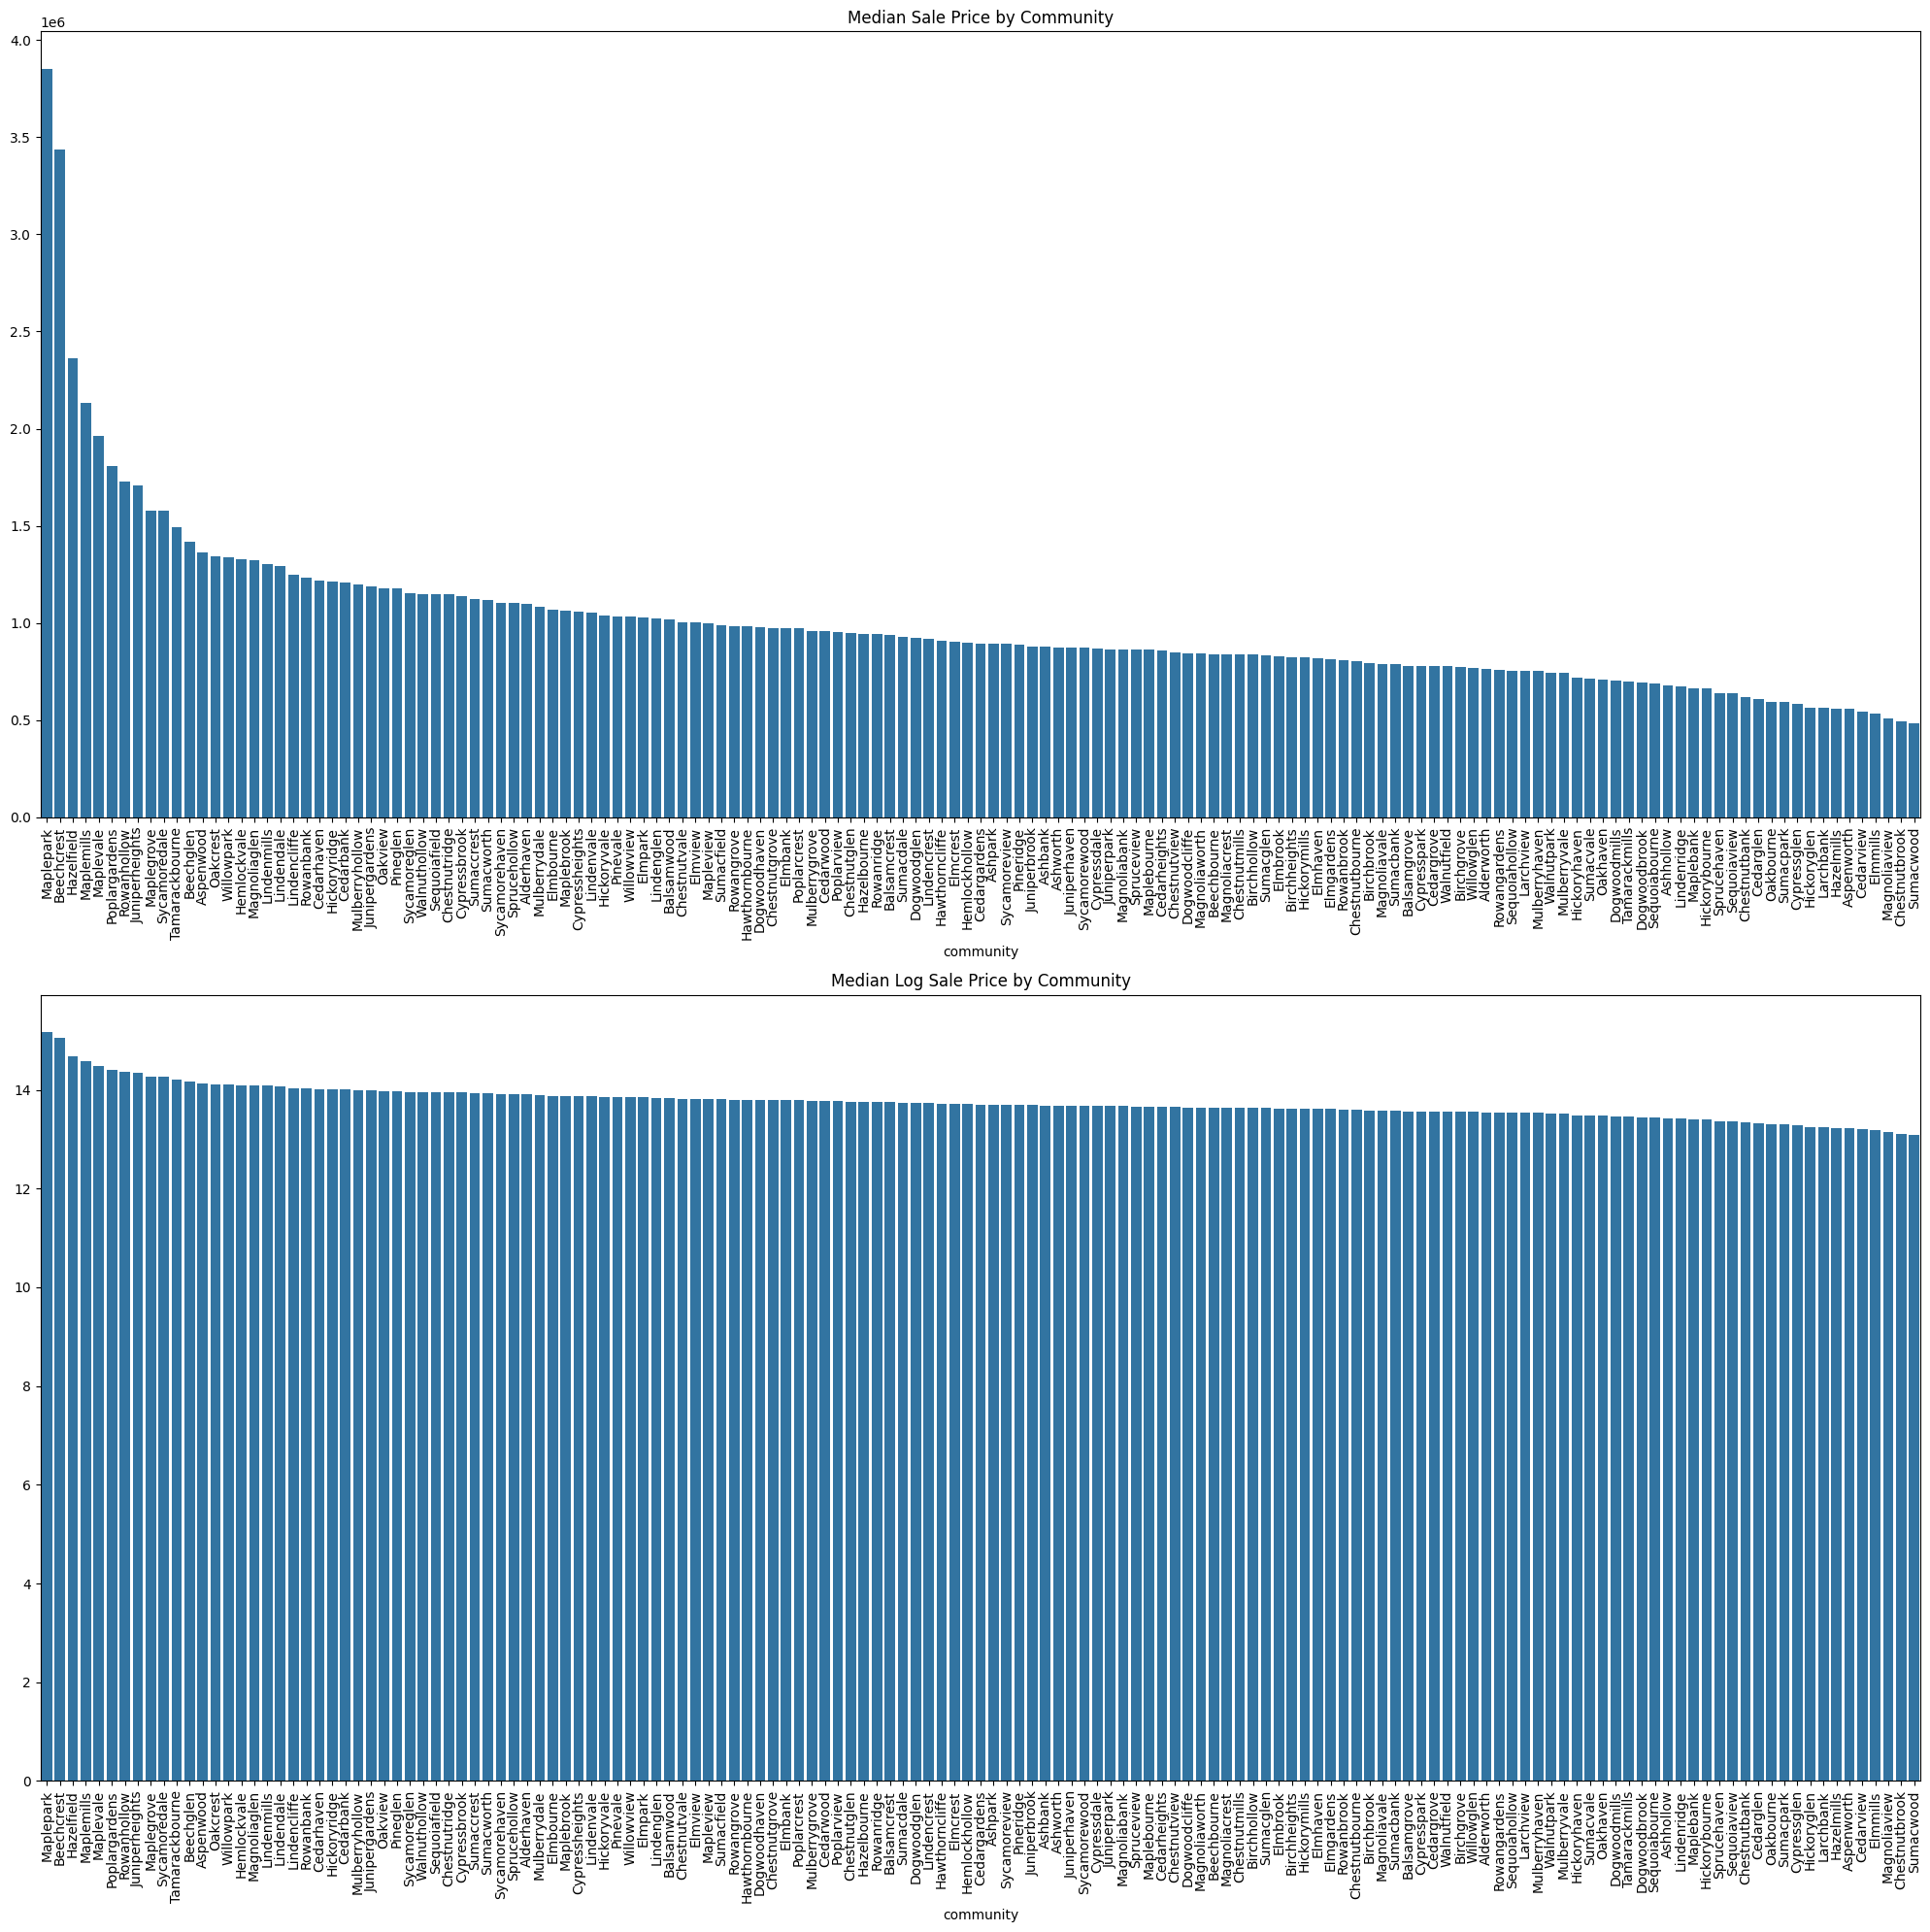

In [17]:
# median sale price ordered by community
df["log_sold_price"] = np.log(df["sold_price"])

median_sold_prices = df.groupby("community")["sold_price"].median().sort_values(ascending=False)
median_sold_prices_log = df.groupby("community")["log_sold_price"].median().sort_values(ascending=False)

fig, axes = plt.subplots(2, 1, figsize=(20, 20))
sns.barplot(x=median_sold_prices.index, y=median_sold_prices.values, ax=axes[0])
axes[0].set_title("Median Sale Price by Community")
axes[0].tick_params(axis="x", rotation=90)
sns.barplot(x=median_sold_prices_log.index, y=median_sold_prices_log.values, ax=axes[1])
axes[1].set_title("Median Log Sale Price by Community")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

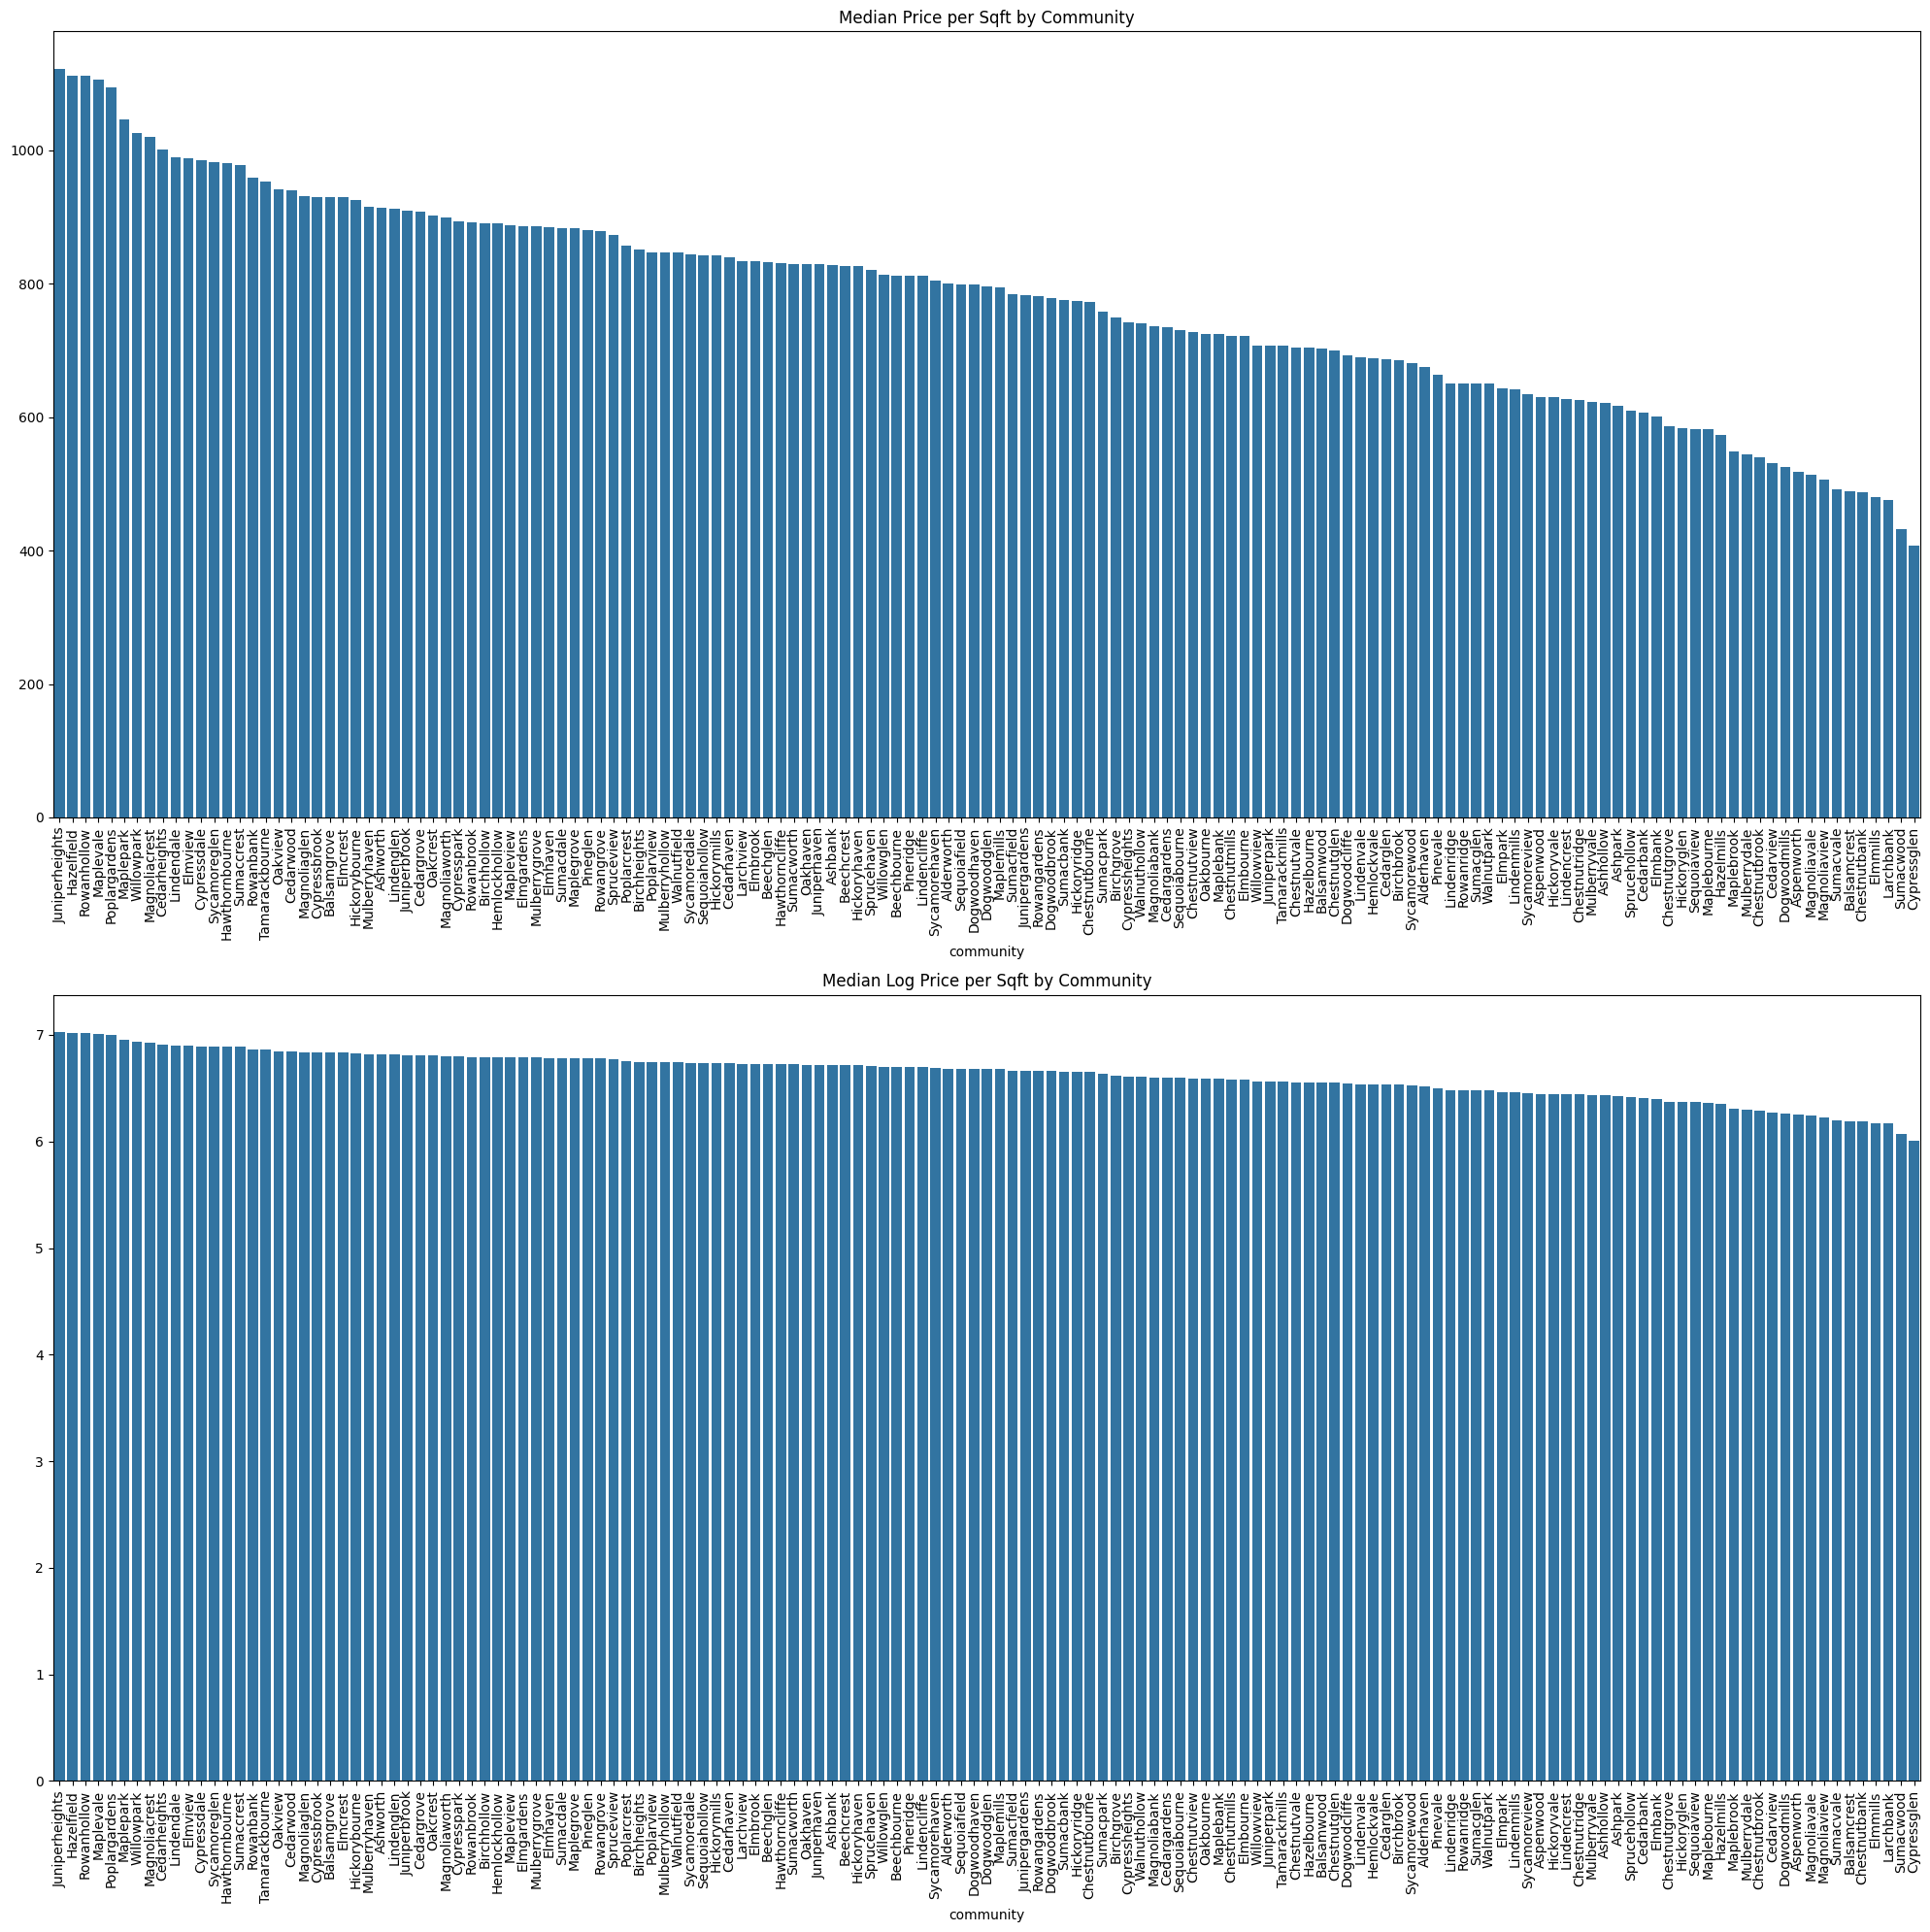

In [14]:
# Median price per sqft by community
df["price_per_sqft"] = df["sold_price"] / df["sqft"]
df["log_sale_price_per_sqft"] = np.log(df["price_per_sqft"])

median_price_per_sqft = df.groupby("community")["price_per_sqft"].median().sort_values(ascending=False)
median_price_per_sqft_log = df.groupby("community")["log_sale_price_per_sqft"].median().sort_values(ascending=False)

fig, axes = plt.subplots(2, 1, figsize=(20, 20))
sns.barplot(x=median_price_per_sqft.index, y=median_price_per_sqft.values, ax=axes[0])
axes[0].set_title("Median Price per Sqft by Community")
axes[0].tick_params(axis="x", rotation=90)
sns.barplot(x=median_price_per_sqft_log.index, y=median_price_per_sqft_log.values, ax=axes[1])
axes[1].set_title("Median Log Price per Sqft by Community")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()


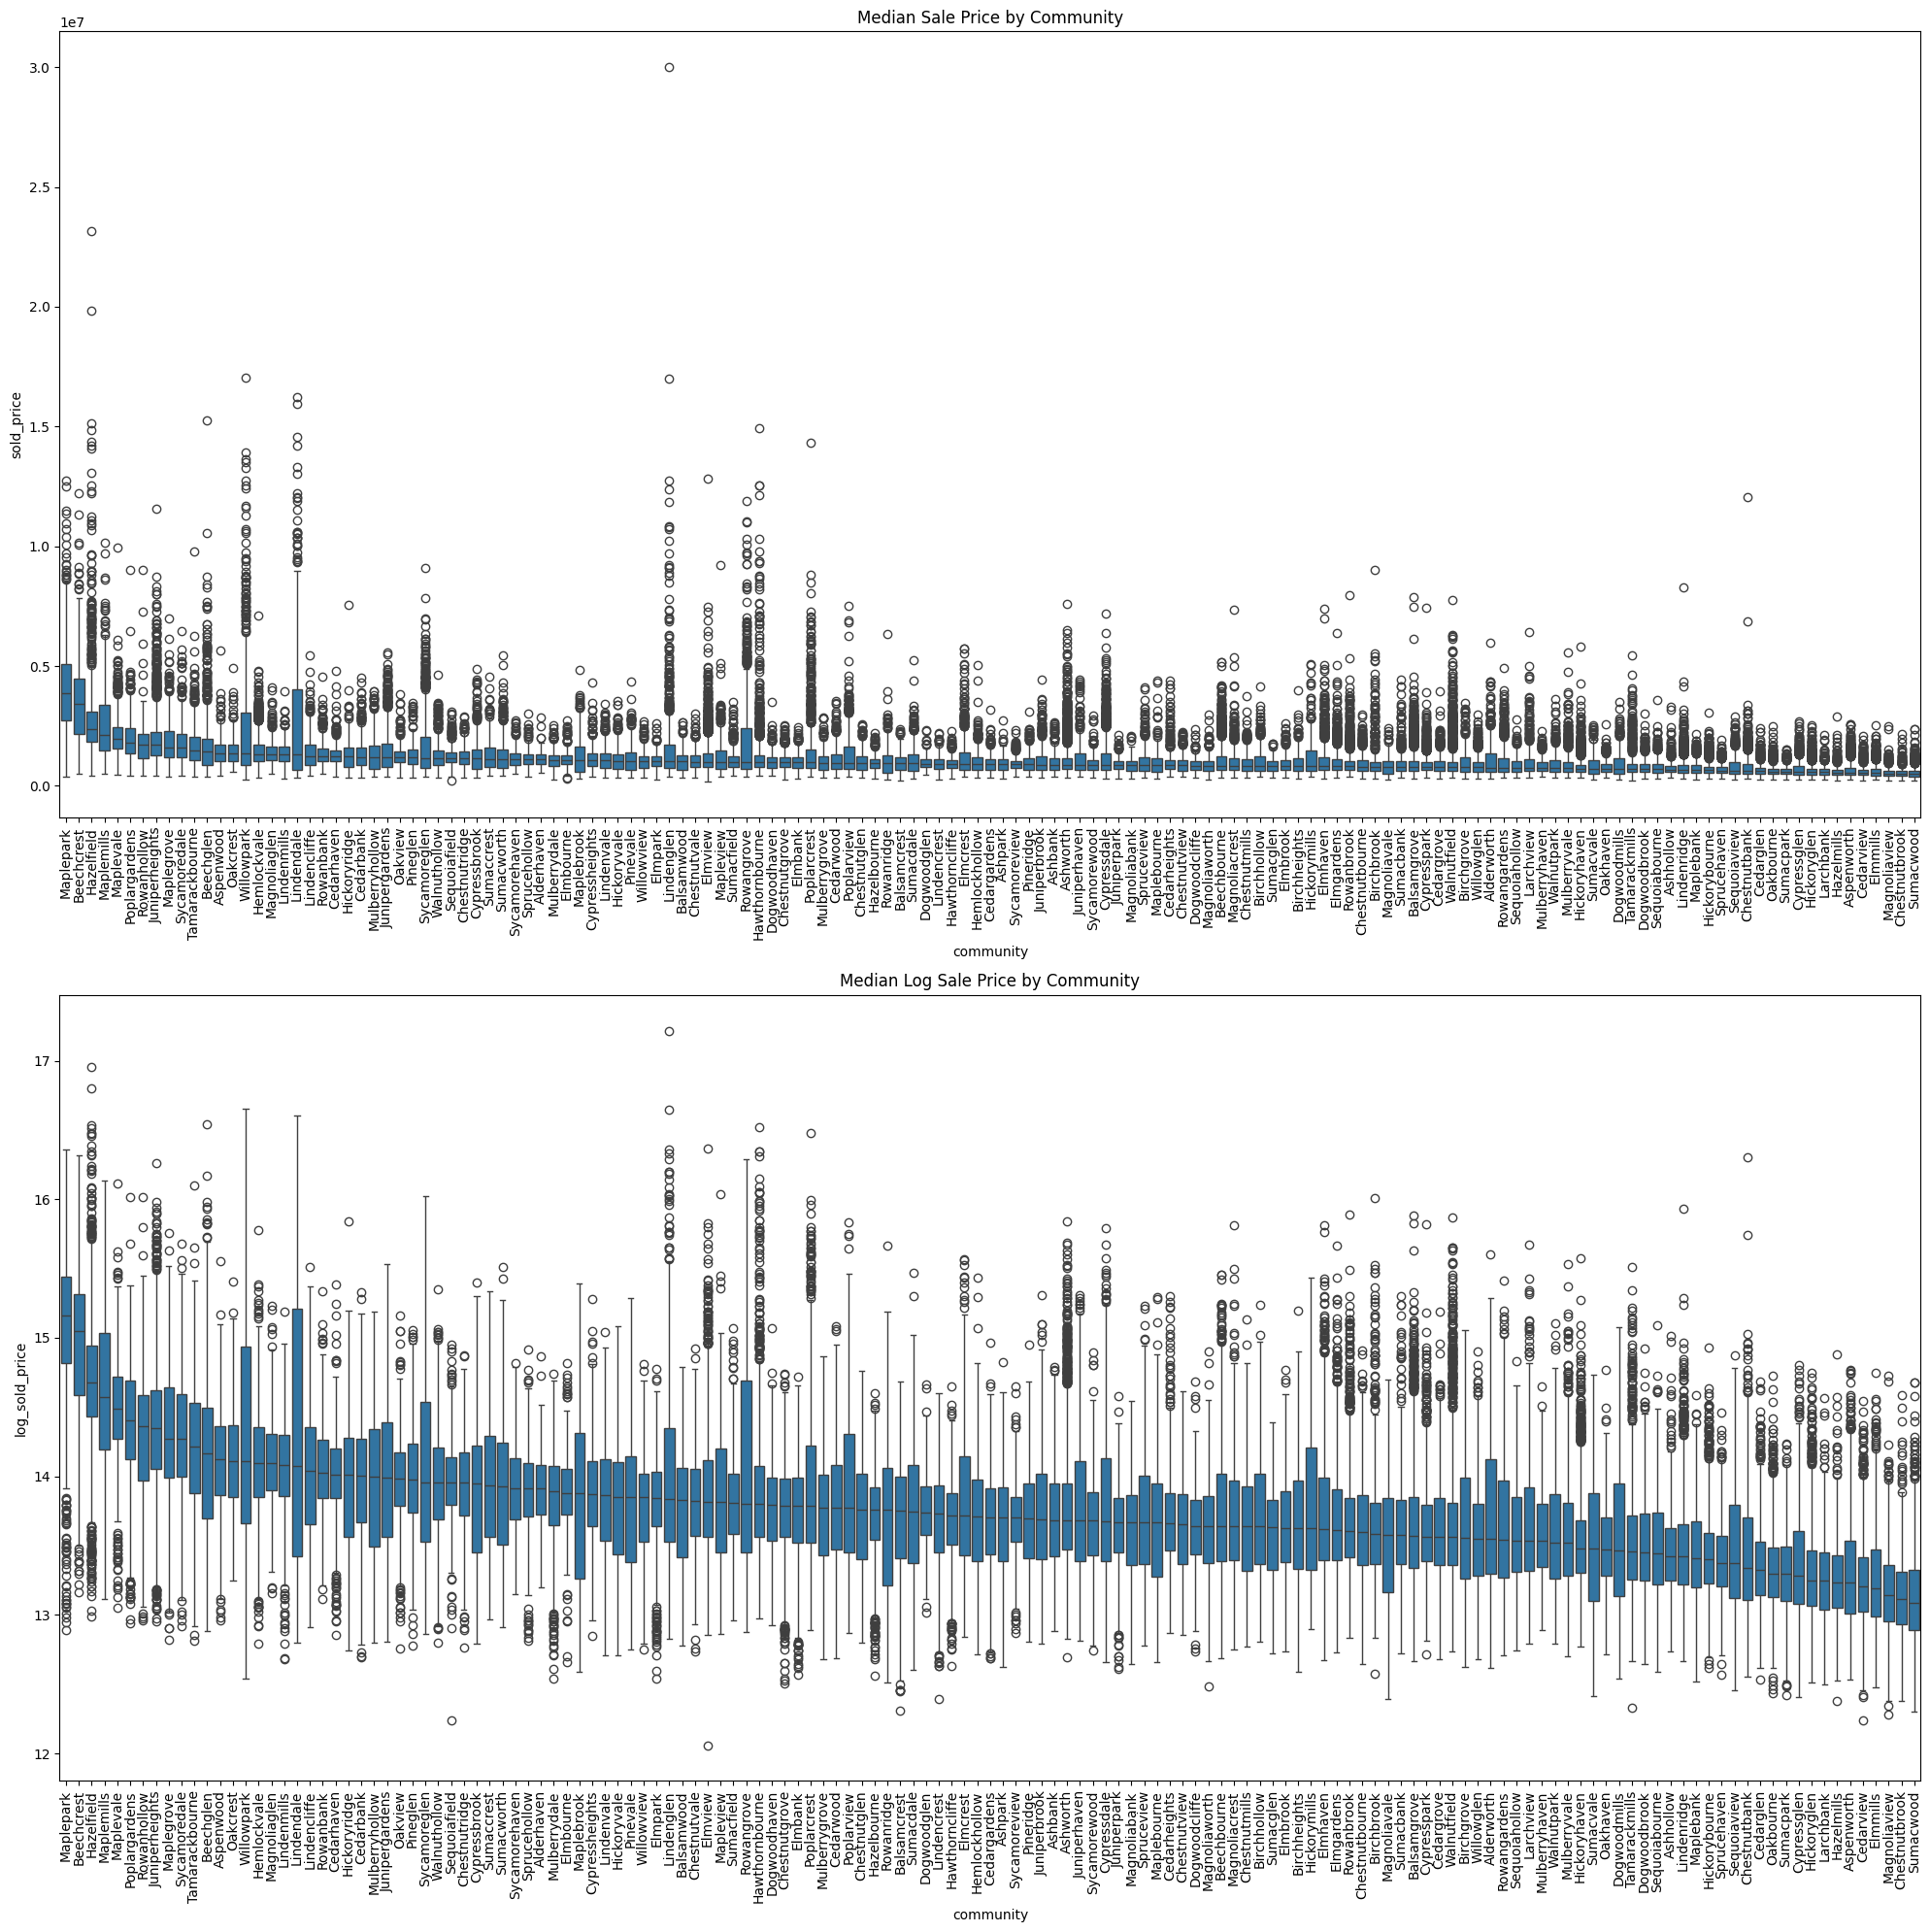

In [18]:
# more about sales price by community:
sold_price = df.groupby("community")["sold_price"].median().sort_values(ascending=False)
log_sold_price = df.groupby("community")["log_sold_price"].median().sort_values(ascending=False)

fig, axes = plt.subplots(2, 1, figsize=(20, 20))
sns.boxplot(x="community", y="sold_price", data=df, ax=axes[0], order=sold_price.index)
axes[0].set_title("Median Sale Price by Community")
axes[0].tick_params(axis="x", rotation=90)
sns.boxplot(x="community", y="log_sold_price", data=df, ax=axes[1], order=log_sold_price.index)
axes[1].set_title("Median Log Sale Price by Community")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

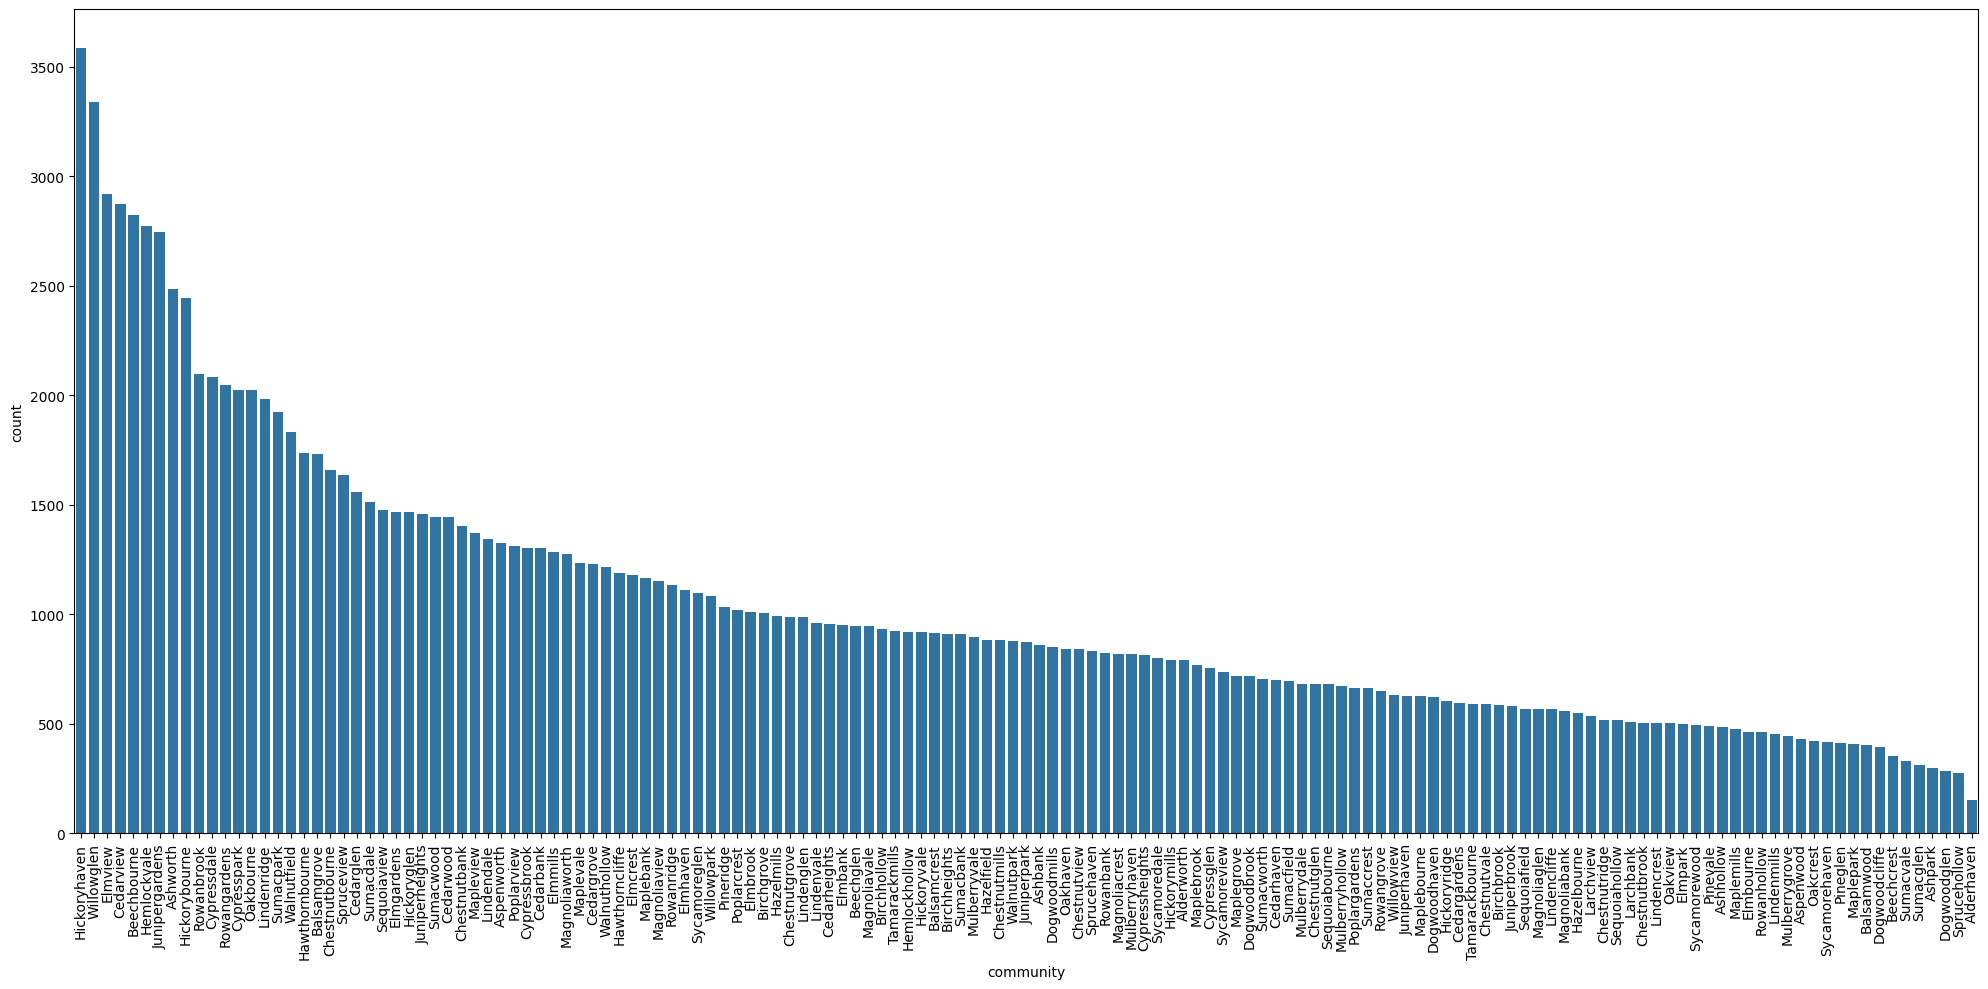

In [22]:
# Distribution of Community
fig = plt.figure(figsize=(20, 10))
sns.countplot(x="community", data=df, order=df["community"].value_counts().index)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [24]:
print(df["community"].value_counts().min())
print(df["community"].value_counts().median())
print(df["community"].value_counts().max())

155
875.0
3584


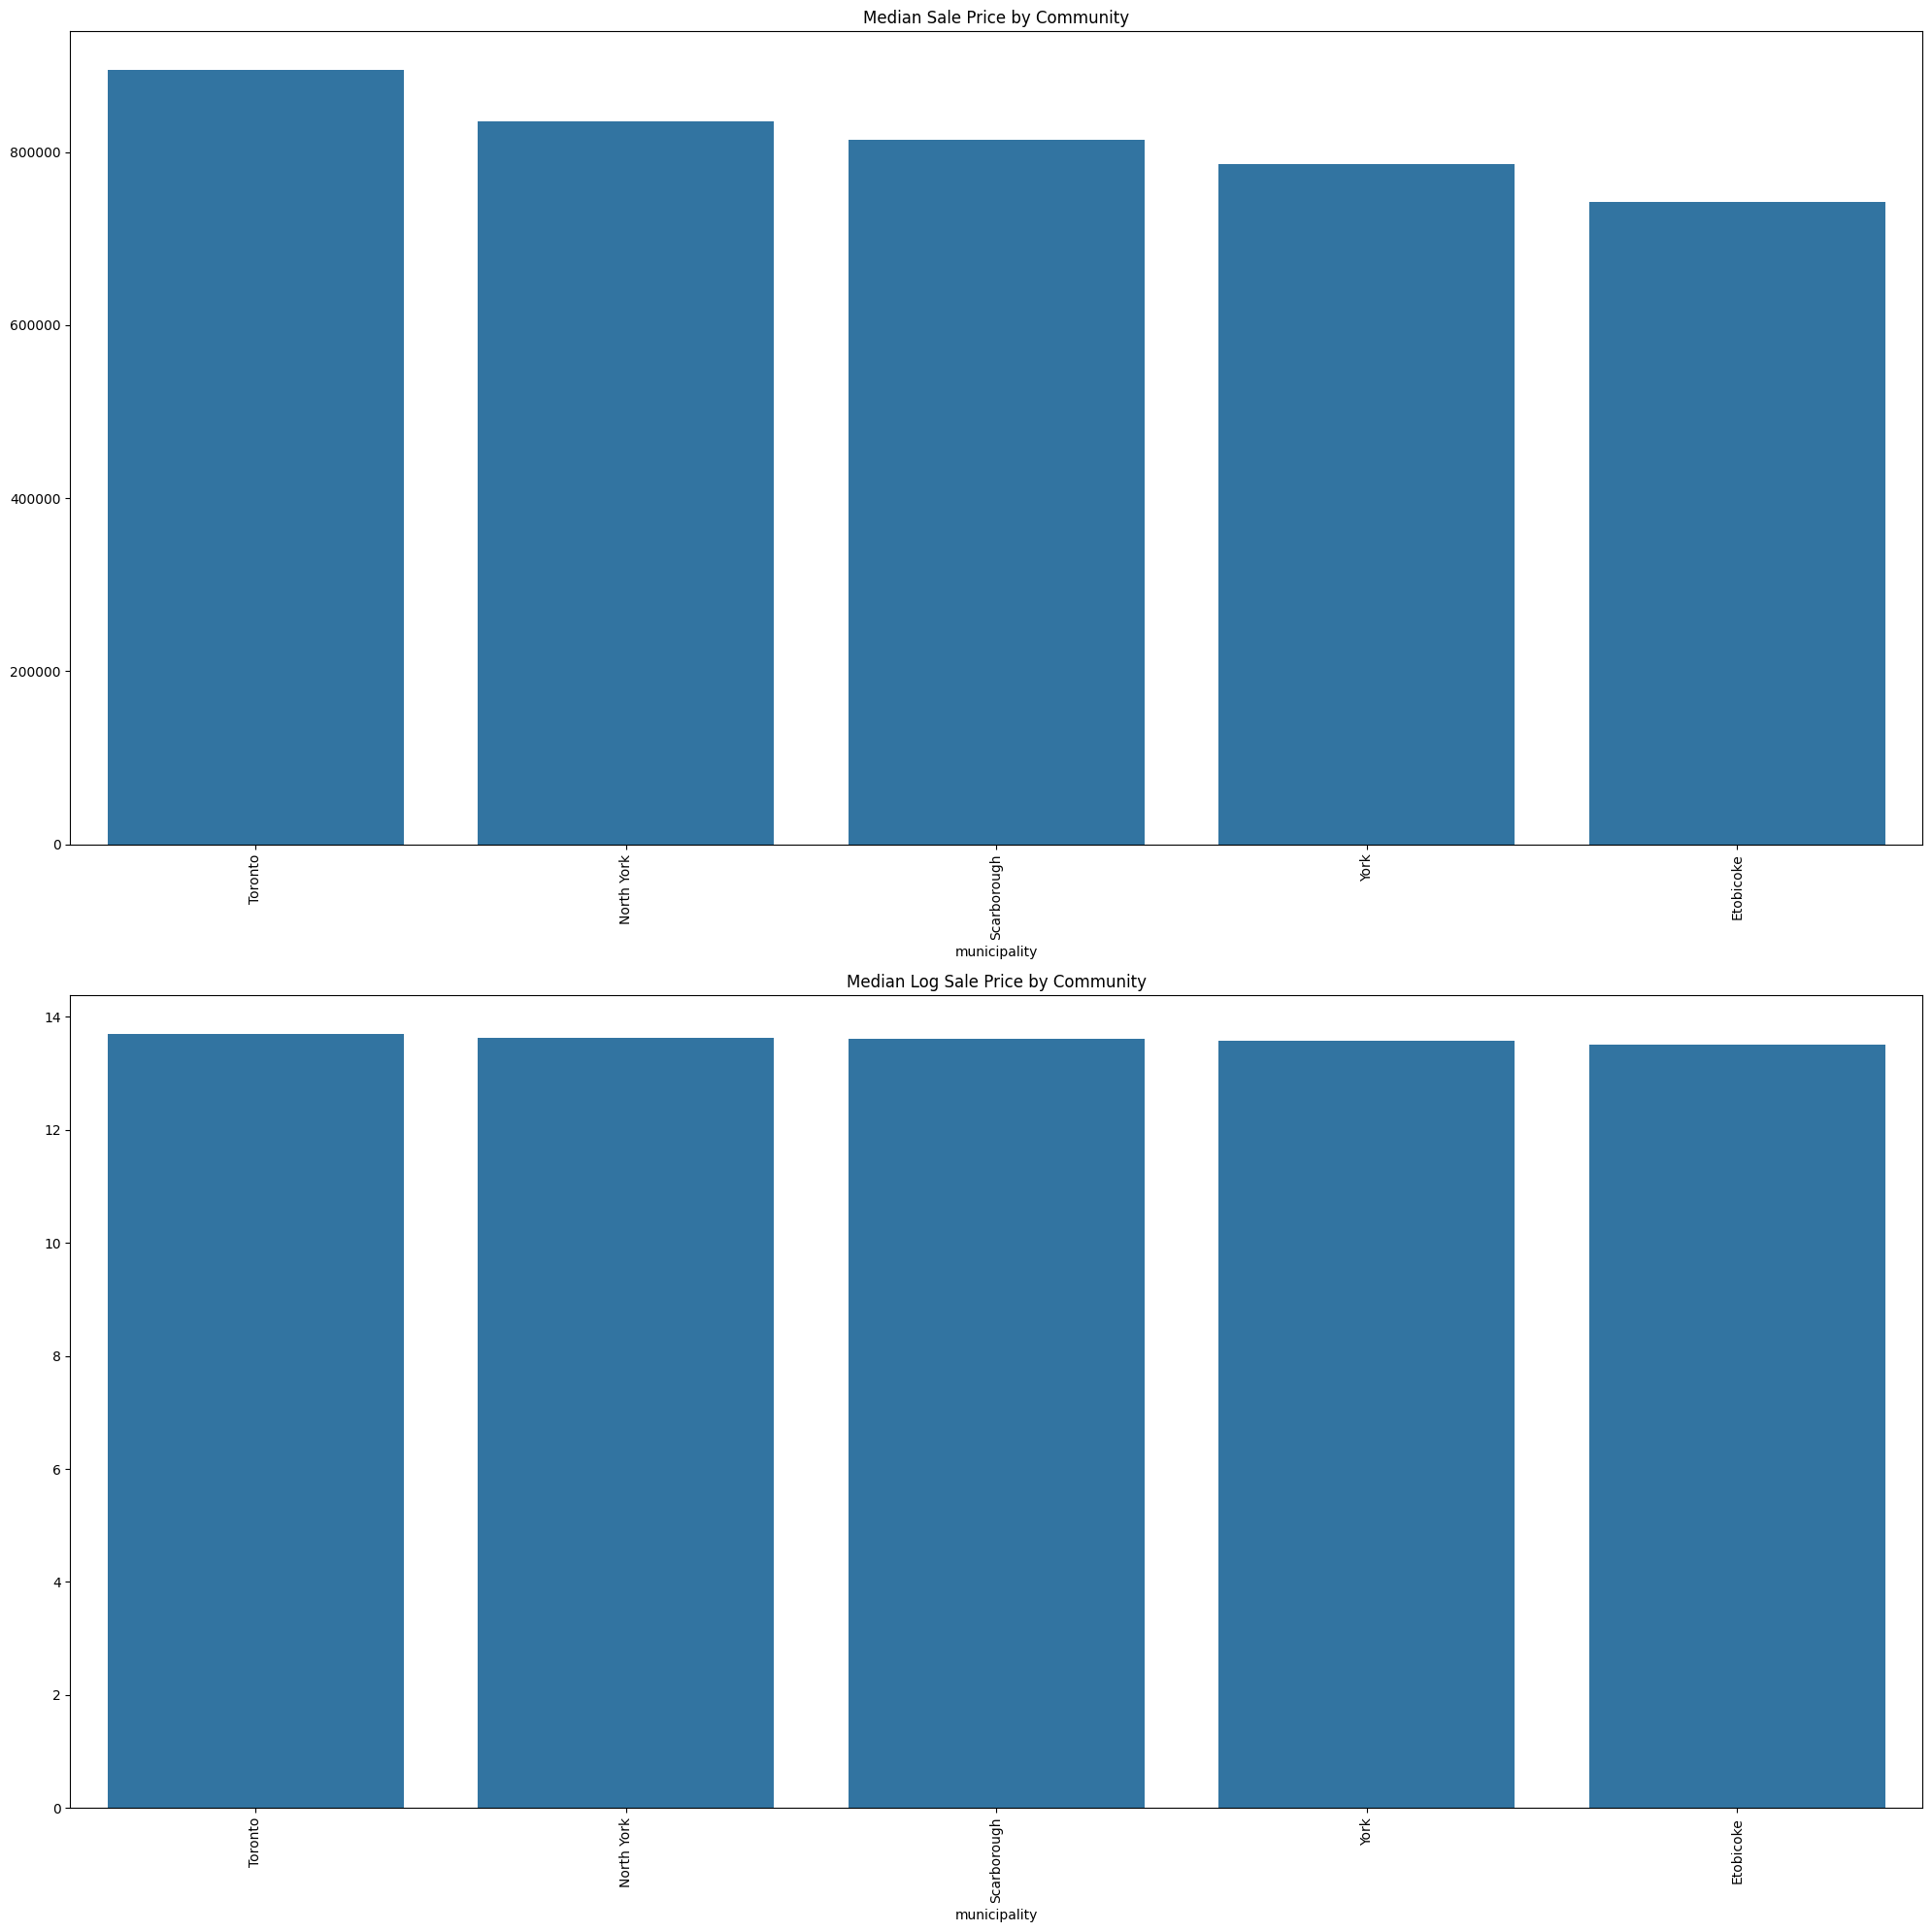

In [ ]:
# median sale price ordered by community
df["log_sold_price"] = np.log(df["sold_price"])

median_sold_prices = df.groupby("municipality")["sold_price"].median().sort_values(ascending=False)
median_sold_prices_log = df.groupby("municipality")["log_sold_price"].median().sort_values(ascending=False)

fig, axes = plt.subplots(2, 1, figsize=(20, 20))
sns.barplot(x=median_sold_prices.index, y=median_sold_prices.values, ax=axes[0])
axes[0].set_title("Median Sale Price by Municipality")
axes[0].tick_params(axis="x", rotation=90)
sns.barplot(x=median_sold_prices_log.index, y=median_sold_prices_log.values, ax=axes[1])
axes[1].set_title("Median Log Sale Price by Municipality")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()